# Unidro MineProblem: Exploratory Data Analysis & RQD Assessment

# Part 1: New Job (Exploratory Data Analysis)

In [7]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

## Data Preparation

### Dataset Paths & Automatic Downloader
it runs directly on the local `data/` folder included in the project package.

In [8]:
# Dataset paths configuration
DATA_DIR = './data'
TRAIN_DIR = os.path.join(DATA_DIR, 'train')
TEST_DIR = os.path.join(DATA_DIR, 'test-rqd')
FROM_TO_PATH = os.path.join(DATA_DIR, 'from-to-rqd.xlsx')
LABEL_PATH = os.path.join(DATA_DIR, 'label.xlsx')

## Exploratory Data Analysis (EDA)

$$
\Large
\begin{aligned}
&\text{Run Length } (l_t) = \text{To} - \text{From} \\
&\text{Image ID Format} = \text{MineID}-\text{BoreholeID}-\text{BoxNumber}.\text{jpg}
\end{aligned}
$$

In [9]:
class MineDataExplorer:
    def __init__(self, train_dir, from_to_path):
        self.train_dir = train_dir
        self.from_to_path = from_to_path
        self.image_files = []
        self.train_boreholes = set()
        self.df_from_to = None
        self.df_train_runs = None

    def load_train_images(self):
        # Load all valid image files in train directory
        all_files = os.listdir(self.train_dir)
        self.image_files = [
            f for f in all_files 
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]
        # Extract MineID-BoreholeID from image filename: e.g., M3-BH130-1.jpg -> M3-BH130
        self.train_boreholes = {
            '-'.join(os.path.splitext(f)[0].split('-')[:2]) 
            for f in self.image_files
        }
        return len(self.image_files), len(self.train_boreholes)

    def load_run_table(self):
        # Load Excel file containing RunId, From, To
        self.df_from_to = pd.read_excel(self.from_to_path)

        # Clean column names
        self.df_from_to.columns = self.df_from_to.columns.astype(str).str.strip()
        self.df_from_to.columns = self.df_from_to.columns.str.lower()
        
        # RunId structure: MineID-BoreholeID-BoxNumber-RunNumber (e.g., M3-BH130-1-3)
        self.df_from_to['borehole_id'] = self.df_from_to['runid'].apply(
            lambda x: '-'.join(str(x).split('-')[:2])
        )
        
        self.df_from_to['image_name'] = self.df_from_to['runid'].apply(
            lambda x: '-'.join(str(x).split('-')[:3])
        )
        
        self.df_from_to['run_length'] = (
            self.df_from_to['to'] - self.df_from_to['from']
        )
        # Filter rows belonging to the train set boreholes
        train_img_prefixes = {os.path.splitext(f)[0] for f in self.image_files}
        mask = (
            self.df_from_to['image_name'].isin(train_img_prefixes) | 
            self.df_from_to['borehole_id'].isin(self.train_boreholes)
        )
        self.df_train_runs = self.df_from_to[mask].copy()
        if self.df_train_runs.empty:
            self.df_train_runs = self.df_from_to.copy()
        return self.df_train_runs

    def compute_statistics(self):
        n_images, n_boreholes = self.load_train_images()
        df_runs = self.load_run_table()

        # Q3: Integer part of largest Run length in from-to-rqd.xlsx
        max_run_length = int(self.df_from_to['run_length'].max())

        # Q4: Borehole with greatest depth (To) in from-to-rqd.xlsx
        max_to_idx = self.df_from_to['to'].idxmax()
        deepest_borehole = self.df_from_to.loc[max_to_idx, 'borehole_id']

        return {
            'n_images': n_images,
            'n_boreholes': n_boreholes,
            'max_run_length': max_run_length,
            'deepest_borehole': deepest_borehole
        }

    def save_submission(self, stats, output_path='output.txt'):
        lines = [
            str(stats['n_images']),
            str(stats['n_boreholes']),
            str(stats['max_run_length']),
            str(stats['deepest_borehole'])
        ]
        with open(output_path, 'w', encoding='utf-8') as f:
            f.write('\n'.join(lines))
        return lines

### Computing Answers & Generating `output.txt`

In [10]:
explorer = MineDataExplorer(train_dir=TRAIN_DIR, from_to_path=FROM_TO_PATH)
stats = explorer.compute_statistics()
submission_lines = explorer.save_submission(stats, output_path='output.txt')

print("Part 1 Results (saved to output.txt):")
print("-" * 40)
print(f"1. Number of train images     : {stats['n_images']}")
print(f"2. Number of unique boreholes : {stats['n_boreholes']}")
print(f"3. Max Run length (int part)  : {stats['max_run_length']}")
print(f"4. Deepest borehole (max To)  : {stats['deepest_borehole']}")

Part 1 Results (saved to output.txt):
----------------------------------------
1. Number of train images     : 158
2. Number of unique boreholes : 6
3. Max Run length (int part)  : 3
4. Deepest borehole (max To)  : M3-BH3301


### Visualizing Sample Core Box & Run Length Distribution

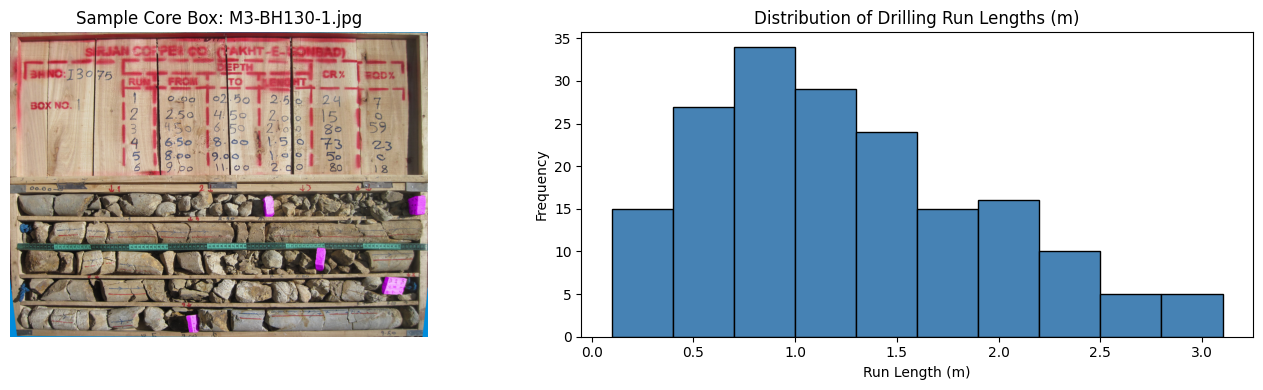

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Plot 1: Sample Core Box Image
sample_img_path = os.path.join(TRAIN_DIR, explorer.image_files[0])
sample_img = Image.open(sample_img_path)
axes[0].imshow(sample_img)
axes[0].set_title(f"Sample Core Box: {explorer.image_files[0]}")
axes[0].axis('off')

# Plot 2: Run Length Distribution
axes[1].hist(explorer.df_from_to['run_length'], bins=10, color='steelblue', edgecolor='black')
axes[1].set_title("Distribution of Drilling Run Lengths (m)")
axes[1].set_xlabel("Run Length (m)")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()